# 3-fish recording: EODs with the emitter next to each electrode pair

Good-frame EODs (mask QC and SLEAP both good) where:
- the emitter (fish 0) is **within 5 cm of either electrode of the pair** (its mask, edge to electrode). Every electrode has an
  electrode of another pair 2–7 cm away, so the pair need not be the nearest one, and one EOD can count for two pairs;
- **both other fish are at least 10 cm away** (mask edge to edge, `gap_cm` of `EOD_assignment_3_fish_conductivities.ipynb`).

For each of the 10 pairs: 5 such EODs at random (`default_rng(0)`), from frames at least 1 s apart. Draws where Denis' SLEAP keypoints
do not land on the masks his A/B/C labels map to are skipped, so his midlines are drawn on the right fish.

**Fallback.** In this recording fish 0 never comes within 5 cm of pair 2 or pair 3 while the other fish are 10 cm away (in no frame
group). A pair with fewer than 5 usable EODs within 5 cm is filled with the closest good-frame EODs farther than 5 cm (other fish
still ≥ 10 cm away, frames still 1 s apart); their titles and file names say "beyond 5 cm".

Figures as in `EOD_examples_mine_vs_Denis.ipynb`:
- **my model**: BEM conductivities, sink at the tail tip, sign fixed (blue);
- **Denis**: his latest run with his own midline (orange);
- the pair is ringed in red in the tank, and its column title is red.

The first table gives, over all EODs within 5 cm of each pair, the % correct of my model, of Denis with his own midline and of Denis
with my mask midline.

In [1]:
import os, pickle, re, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mask_metrics as mm                         # ZEUS crop unpacking (sets the Agg backend...)
%matplotlib inline
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.patheffects as pe
from midline_methods import fish_midline_with_head
from eod_assign import load_electrode_pairs, peak_pattern, rank1_pattern

REC = {
    '3-fish': dict(
        data='data/3_fish_silent', eod_csv='Assigned_Data_3fish_2024-10-15T14_12_25.csv',
        track='elephantnose_20241015T141225_tracking_final.pkl', video='video2024-10-15T14_12_25.avi',
        electrodes='data/electrodes/electrodes_signed_px_coord_3-fish.csv',
        res='results/eod_ground_truth_3fish/conductivities',
        cache='model_voltages_N150_sinks0and0.05_elc5c81b_bem_a453a8.pkl',
        denis_pkl='results/eod_assignment_3_fish_silent/electrodes_3-fish/Assigned_Data_3fish_2024-10-15T14_12_25.pkl',
        fish=(0, 1, 2), emitter=0, denis_map={'A': 1, 'B': 2, 'C': 0},
        fish_color={0: '#E0B000', 1: '#D45087', 2: '#2E8B57'}),
    '2-fish': dict(
        data='data/2_fish_silent', eod_csv='Data_1fish_2024-02-13T14_33_21.csv',
        track='elephantnose_20240213T143321_tracking_final.pkl', video='video2024-02-13T14_33_21.avi',
        electrodes='data/electrodes/electrodes_signed_px_coord_2-fish.csv',
        res='results/eod_ground_truth/conductivities',
        cache='model_voltages_N150_sinks0and0.05_el46ee63_bem_a453a8.pkl',
        denis_pkl='results/eod_assignment_2_fish_silent/electrodes_2-fish/Assigned_Data_1fish_2024-02-13T14_33_21.pkl',
        fish=(0, 1), emitter=1, denis_map={'A': 1, 'B': 0},
        fish_color={0: '#2E8B57', 1: '#D45087'}),
}
MINE = 'BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip'   # column of eod_assignments.csv
DENIS = "Denis' pipeline (latest run)"
C_MINE, C_DENIS, C_REC = '#1F5FBF', '#E8710A', 'k'   # my model blue, Denis orange, recorded black
PX_PER_CM = 912 / 60                                  # Denis' pixel2cm
FS = 50000.0                                          # electrode sampling rate (Hz)
n_poles = 100
OUTCOMES = ['both right', 'only mine right', 'only Denis right', 'both wrong']
N_BINS, SEED = 5, 0
OUTLINE = [pe.withStroke(linewidth=3, foreground='k')]
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp
from scipy.spatial import cKDTree

NEAR_CM, FAR_CM, MIN_SEP_FRAMES, N_PER_PAIR = 5.0, 10.0, 50, 5   # thresholds; 50 frames = 1 s
C_PAIR = '#C00000'
DENIS_MASK = "Denis' pipeline with my mask midline"               # column of eod_assignments.csv
OUT = 'results/eod_ground_truth_3fish/conductivities/examples_near_each_pair'
os.makedirs(OUT, exist_ok=True)

In [2]:
def load_recording(name):
    '''Everything the examples need for one recording, as a dict.'''
    c = dict(REC[name], name=name)
    df = pd.read_csv(f"{c['data']}/{c['eod_csv']}")
    pat = re.compile(r'electrode_(\d+)_t(?:ime)?_([mp]?)(\d+)$')       # sample k (2-fish) or m12 ... 0 ... p12 (3-fish)
    cols = {}
    for col in df.columns:
        m = pat.match(col)
        if m: cols.setdefault(int(m[1]), []).append(((-1 if m[2] == 'm' else 1) * int(m[3]), col))
    c['trace_cols'] = {p: [col for _, col in sorted(v)] for p, v in sorted(cols.items())}
    assert len(c['trace_cols']) == 10 and len({len(v) for v in c['trace_cols'].values()}) == 1
    with open(f"{c['data']}/{c['track']}", 'rb') as f:
        trk = pickle.load(f)
    c.update(df=df, frames=trk['frames'], P=trk['shape'][0], fps=trk['fps'])
    c['pairs'] = load_electrode_pairs(c['electrodes'], c['P'])
    c['pair_ids'] = [pid for pid, _, _ in c['pairs']]
    c['assigned'] = pd.read_csv(f"{c['res']}/eod_assignments.csv", index_col='row')
    c['cache'] = pd.read_pickle(f"{c['res']}/{c['cache']}")
    c['den'] = pd.read_pickle(c['denis_pkl'])
    n = len(df)
    assert len(c['assigned']) == len(c['cache']) == len(c['den']) == n
    for t in (c['assigned'].Frame, c['cache'].frame, c['den'].Frame):
        assert (np.asarray(t) == df.Frame.to_numpy()).all()
    return c

def recorded_pair_traces(c, i):
    '''(n_pairs, n_samp) recorded voltages of EOD row i, each pair demeaned.'''
    V = np.stack([c['df'].loc[i, c['trace_cols'][p]].to_numpy(float) for p in c['pair_ids']])
    return V - np.nanmean(V, axis=1, keepdims=True)

def frame_masks(c, k):
    '''(n_fish, P, P) full-frame bool masks of frame k, indexed by fish label (empty where a fish has no mask).'''
    P = c['P']; m = np.zeros((len(c['fish']), P, P), bool)
    fr = c['frames'][k]
    for l, p, (y0, y1, x0, x1) in zip(fr['labels'], fr['masks'], fr['boxes']):
        if l in c['fish']: m[l, y0:y1, x0:x1] = mm.unpack_crop(p, (y0, y1, x0, x1))
    return m

def video_frame(c, k):
    '''Grayscale (P, P) frame k of the raw video (ffmpeg).'''
    out = subprocess.run(['ffmpeg', '-v', 'error', '-ss', f"{k / c['fps']:.4f}", '-i', f"{c['data']}/{c['video']}", '-frames:v', '1',
                          '-f', 'rawvideo', '-pix_fmt', 'gray', '-'], capture_output=True, check=True).stdout
    return np.frombuffer(out, np.uint8).reshape(c['P'], c['P'])

def fish_midlines(fm):
    '''Midline (n_poles + 1, 2) in tank coords (row, col) / (P - 1), tail -> head, of every fish; None where it fails.'''
    out = []
    for m in fm:
        try:
            mid = fish_midline_with_head(m, n_ctrl=n_poles + 1)['midline'] if m.any() else None
            out.append(mid if mid is not None and np.isfinite(mid).all() else None)
        except Exception:
            out.append(None)
    return out

def denis_mask_of(c, d, X, fm, min_score=0.5):
    '''Mask label holding most confident SLEAP keypoints of Denis' fish X (-1 if none lies on a mask).'''
    votes = []
    for kp in ('mouth', 'head', 'middle', 'tail'):
        if not d[f'score_{kp}_{X}'] > min_score: continue
        x, y = np.round(np.asarray(d[f'{kp}_{X}']) * PX_PER_CM).astype(int)
        if 0 <= x < c['P'] and 0 <= y < c['P']: votes += [f for f in c['fish'] if fm[f][y, x]]
    return max(set(votes), key=votes.count) if votes else -1

def my_patterns(c, i):
    '''Recorded peak pattern r (max |r| = 1) and my model patterns (n_fish, n_pairs), sign fixed (x -1), max |u| = 1.'''
    r = np.asarray(c['cache'].v_rec[i]); r = r / np.abs(r).max()
    U = -np.asarray(c['cache']['u_sink0'][i]); U = U / np.abs(U).max(axis=1, keepdims=True)
    return r, U

In [3]:
def plot_example(c, i, head, path, pair=None):
    '''Tank + voltages figure of EOD row i; `head` starts the title, `pair` (id) is highlighted, saved to `path`.'''
    df, den, P, em, fish = c['df'], c['den'], c['P'], c['emitter'], c['fish']
    k = int(df.Frame[i]); fm = frame_masks(c, k); mids = fish_midlines(fm); dp = den.loc[i]
    letter = {f: X for X, f in c['denis_map'].items()}                       # mask label -> Denis' fish
    V = recorded_pair_traces(c, i); r, ts = peak_pattern(V); rmax = np.abs(r).max()
    r_c, U = my_patterns(c, i)
    assert np.allclose(r / rmax, r_c)                                        # same recording as the cached run
    w = rank1_pattern(V)[1]; w = w / w[ts]                                   # EOD waveform, 1 at the peak sample
    t_ms = (np.arange(V.shape[1]) - V.shape[1] // 2) / FS * 1e3
    sigma = np.sign(np.asarray(dp.recorded_PTP) @ r)                         # Denis' peak-to-peak sign -> peak-sample sign
    mine_pick, den_pick = int(c['assigned'].loc[i, f'fish | {MINE}']), int(c['assigned'].loc[i, f'fish | {DENIS}'])
    d_mine = np.linalg.norm(U - r_c, axis=1)

    nf = len(fish)
    fig = plt.figure(figsize=(25, 3.0 * nf + 2.6))
    gs = fig.add_gridspec(nf, 12, width_ratios=[2.7 * nf / 3 + 2.6, 2.6] + [1] * 10, wspace=0.1, hspace=0.3)

    # tank
    a = fig.add_subplot(gs[:, 0])
    a.imshow(video_frame(c, k), cmap='gray')
    over = np.zeros((P, P, 4))
    for f in fish: over[fm[f]] = to_rgba(c['fish_color'][f], 0.45)
    a.imshow(over)
    for f in fish:
        if mids[f] is not None:
            mid = mids[f] * (P - 1)                                          # (row, col), tail -> head
            a.plot(mid[:, 1], mid[:, 0], color=C_MINE, lw=2, path_effects=OUTLINE)
            a.plot(mid[-1, 1], mid[-1, 0], 'o', color=C_MINE, mec='w', ms=8)
        dm = np.asarray(dp[f'currents_locations_{letter[f]}']) * PX_PER_CM   # (x, y) px, tail -> mouth
        a.plot(dm[:, 0], dm[:, 1], color=C_DENIS, lw=2, ls='--', path_effects=OUTLINE)
        a.plot(dm[-1, 0], dm[-1, 1], 's', color=C_DENIS, mec='w', ms=7)
        for kp, mk in (('mouth', '^'), ('head', 'o'), ('middle', 's'), ('tail', 'v')):
            x, y = np.asarray(dp[f'{kp}_{letter[f]}']) * PX_PER_CM
            a.plot(x, y, mk, color='w', mec='k', ms=6, mew=1)
        if fm[f].any():
            yx = np.argwhere(fm[f]); y, x = yx[np.argmax(yx[:, 0])]          # label just below the mask
            a.text(x, min(y + 25, P - 5), f"fish {f}" + (' (emitter)' if f == em else ''), color='w', fontsize=11,
                   fontweight='bold', ha='center', va='top', path_effects=OUTLINE)
    for pid, pp, pm in c['pairs']:                                           # electrodes: pair number and polarity
        for pt, sgn in ((pp, '+'), (pm, '−')):
            y, x = pt * (P - 1)
            a.plot(x, y, 'o', color='w', mec='k', ms=5)
            off = np.array([P / 2 - x, P / 2 - y]); off = 30 * off / np.linalg.norm(off)
            a.text(x + off[0], y + off[1], f'{pid}{sgn}', color='k', fontsize=8, ha='center', va='center',
                   bbox=dict(boxstyle='round,pad=0.1', fc='w', ec='none', alpha=0.85))
    for pid, pp, pm in c['pairs']:                                           # ring the highlighted pair's electrodes
        if pid == pair:
            for pt in (pp, pm): a.plot(*(pt * (P - 1))[::-1], 'o', ms=20, mfc='none', mec=C_PAIR, mew=2.5)
    a.set(xlim=(-10, P + 10), ylim=(P + 10, -10)); a.set_axis_off()
    a.legend(handles=[Patch(color=c['fish_color'][f], alpha=0.6, label=f'mask fish {f}') for f in fish] +
                     [Line2D([], [], color=C_MINE, lw=2, marker='o', mec='w', label='my midline (dot = head)'),
                      Line2D([], [], color=C_DENIS, lw=2, ls='--', marker='s', mec='w', label="Denis' midline (square = head)"),
                      Line2D([], [], marker='^', color='w', mec='k', ls='', label='SLEAP mouth'),
                      Line2D([], [], marker='o', color='w', mec='k', ls='', label='SLEAP head'),
                      Line2D([], [], marker='s', color='w', mec='k', ls='', label='SLEAP middle'),
                      Line2D([], [], marker='v', color='w', mec='k', ls='', label='SLEAP tail'),
                      Line2D([], [], marker='o', color='w', mec='k', ms=5, ls='', label='electrode (pair, polarity)')],
             loc='upper center', bbox_to_anchor=(0.5, -0.005), ncol=2, fontsize=9, frameon=True, facecolor='0.9')

    # voltages: one row per candidate fish
    for row, f in enumerate(fish):
        X = letter[f]
        pd_hat = sigma * np.asarray(dp[f'normalized_predicted_PTP_{X}']); pd_hat = pd_hat / np.abs(pd_hat).max()
        la = fig.add_subplot(gs[row, 1]); la.set_axis_off()
        lines = [(f"fish {f} as emitter" + (' (true)' if f == em else ''), 'k', 'bold'),
                 (f"mine: d = {d_mine[f]:.2f}" + ('  ◀ pick' if f == mine_pick else ''), C_MINE, 'bold' if f == mine_pick else 'normal'),
                 (f"Denis: sim = {dp[f'similarity_{X}']:+.2f}" + ('  ◀ pick' if f == den_pick else ''), C_DENIS,
                  'bold' if f == den_pick else 'normal')]
        for j, (s, col, fw) in enumerate(lines):
            la.text(0.8, 0.68 - 0.2 * j, s, color=col, fontweight=fw, fontsize=10, ha='right', va='center', transform=la.transAxes)
        for kk, pid in enumerate(c['pair_ids']):
            ax = fig.add_subplot(gs[row, 2 + kk])
            ax.axhline(0, color='0.85', lw=0.6)
            ax.plot(t_ms, V[kk] / rmax, color=C_REC, lw=2.2)
            ax.plot(t_ms, U[f, kk] * w, color=C_MINE, lw=1.8)
            ax.plot(t_ms, pd_hat[kk] * w, color=C_DENIS, lw=1.8, ls='--')
            ax.set_ylim(-1.25, 1.25); ax.set_xticks([-0.2, 0, 0.2]); ax.tick_params(labelsize=8)
            if row == 0: ax.set_title(f'pair {pid}', fontsize=10, color=C_PAIR if pid == pair else 'k',
                                      fontweight='bold' if pid == pair else 'normal')
            if kk: ax.set_yticklabels([])
            if row < nf - 1: ax.set_xticklabels([])
            else: ax.set_xlabel('time (ms)', fontsize=9)
            if f in (mine_pick, den_pick):                                   # frame the picked rows
                for sp in ax.spines.values(): sp.set_color('0.3'); sp.set_linewidth(1.2)

    ok = lambda p: '✓' if p == em else '✗'
    fig.suptitle(f"{head} | frame {k} (EOD row {i})\n"
                 f"my pick: fish {mine_pick} {ok(mine_pick)}     Denis' pick: fish {den_pick} {ok(den_pick)}",
                 fontsize=13, y=0.99)
    fig.legend(handles=[Line2D([], [], color=C_REC, lw=2.2, label='recorded (all traces scaled to max |v| = 1)'),
                        Line2D([], [], color=C_MINE, lw=1.8, label='my model'),
                        Line2D([], [], color=C_DENIS, lw=1.8, ls='--', label="Denis' model")],
               loc='lower center', bbox_to_anchor=(0.62, -0.02), ncol=3, fontsize=11, frameon=False)
    fig.savefig(path, dpi=100, bbox_inches='tight')
    plt.show()

## Distance from the emitter to each pair

In [4]:
c = load_recording('3-fish'); A = c['assigned']; em = c['emitter']; P = c['P']
EL = np.array([[pt * (P - 1) for pt in (pp, pm)] for _, pp, pm in c['pairs']])   # (10 pairs, 2 electrodes, (row, col)) px

def pair_distances(k):
    '''(10,) distance (cm) from the emitter's mask to the nearer electrode of each pair in frame k (NaN without a mask).'''
    m = frame_masks(c, k)[em]
    if not m.any(): return np.full(len(EL), np.nan)
    return cKDTree(np.argwhere(m)).query(EL.reshape(-1, 2))[0].reshape(len(EL), 2).min(axis=1) / PX_PER_CM

g = A[A['good frames'] & (A.gap_cm >= FAR_CM)].copy()            # good frames, other fish >= 10 cm away
uf = g.Frame.unique()
with ProcessPoolExecutor(5, mp_context=mp.get_context('fork')) as pool:
    pdist = dict(zip(uf, pool.map(pair_distances, [int(k) for k in uf], chunksize=64)))
D = pd.DataFrame(np.stack([pdist[k] for k in g.Frame]), index=g.index, columns=c['pair_ids'])   # cm

pipes = {'mine (BEM σ, tip)': f'fish | {MINE}', "Denis, his midline": f'fish | {DENIS}', "Denis, my mask midline": f'fish | {DENIS_MASK}'}
summ = {}
for p in c['pair_ids']:
    near = g[D[p] <= NEAR_CM]
    summ[p] = {'n EODs within 5 cm': len(near), 'closest (cm)': D[p].min(),
               **{f'% correct: {nm}': 100 * (near[col] == em).mean() if len(near) else np.nan for nm, col in pipes.items()}}
summ = pd.DataFrame(summ).T.rename_axis('pair')
print(f"{A['good frames'].sum()} good-frame EODs, {len(g)} with the other fish >= {FAR_CM:g} cm away")
display(summ.round(1))

6938 good-frame EODs, 4125 with the other fish >= 10 cm away


,n EODs within 5 cm,closest (cm),"% correct: mine (BEM σ, tip)","% correct: Denis, his midline","% correct: Denis, my mask midline"
pair,,,,,
1,51.0,1.2,94.1,96.1,98.0
2,0.0,9.2,NaN,NaN,NaN
3,0.0,7.8,NaN,NaN,NaN
4,428.0,2.6,94.4,97.7,95.3
5,433.0,0.7,93.3,97.2,94.2
6,271.0,0.2,96.7,95.9,96.3
7,286.0,0.4,97.9,97.2,97.6
8,52.0,1.3,94.2,96.2,98.1
9,453.0,2.7,94.0,97.4,95.4


## Choosing the examples

In [5]:
rng = np.random.default_rng(0); rows = []

def usable(i, picked):
    '''Frame of row i at least 1 s from the picked ones, and Denis' keypoints on the masks his labels map to.'''
    k = int(g.Frame[i])
    if any(abs(k - int(g.Frame[j])) < MIN_SEP_FRAMES for j, _ in picked): return False
    fm = frame_masks(c, k)
    return all(denis_mask_of(c, c['den'].loc[i], X, fm) == f for X, f in c['denis_map'].items())

for p in c['pair_ids']:
    picked = []
    for i in rng.permutation(g.index[D[p] <= NEAR_CM].to_numpy()):          # random within 5 cm
        if usable(i, picked): picked.append((i, True))
        if len(picked) == N_PER_PAIR: break
    if len(picked) < N_PER_PAIR:                                              # fallback: closest beyond 5 cm
        n_near = len(picked); far = D.index[D[p] > NEAR_CM]
        for i in far[np.argsort(D.loc[far, p].to_numpy())]:
            if usable(i, picked): picked.append((i, False))
            if len(picked) == N_PER_PAIR: break
        print(f'pair {p}: {n_near} usable EODs within {NEAR_CM:g} cm, {len(picked) - n_near} closest beyond')
    rows += [(p, i, w) for i, w in sorted(picked, key=lambda t: D.loc[t[0], p])]
ex = pd.DataFrame([{'pair': p, 'row': i, 'frame': int(g.Frame[i]), 'within 5 cm': w, 'fish 0 to pair (cm)': D.loc[i, p],
                    'fish 0 to nearest other fish (cm)': g.gap_cm[i], **{f'pick: {nm}': g.loc[i, col] for nm, col in pipes.items()}}
                   for p, i, w in rows])
display(ex.round(1))

pair 2: 0 usable EODs within 5 cm, 5 closest beyond
pair 3: 0 usable EODs within 5 cm, 5 closest beyond


,pair,row,frame,within 5 cm,fish 0 to pair (cm),fish 0 to nearest other fish (cm),"pick: mine (BEM σ, tip)","pick: Denis, his midline","pick: Denis, my mask midline"
0,1,12869,18897,True,1.7,29.4,0,0,0.0
1,1,10196,15056,True,2.5,19.1,0,0,0.0
2,1,17420,25242,True,2.9,26.1,0,0,0.0
3,1,13004,19043,True,3.1,26.0,0,0,0.0
4,1,18740,29792,True,3.1,10.5,0,0,0.0
5,2,15372,22268,False,9.2,33.5,0,0,0.0
6,2,19750,34061,False,11.8,30.5,0,2,0.0
7,2,5879,9268,False,11.8,14.2,0,2,2.0
8,2,8402,12483,False,13.4,19.7,0,0,0.0
9,2,4877,7354,False,13.5,29.0,0,0,0.0


## Figures

Saved in `results/eod_ground_truth_3fish/conductivities/examples_near_each_pair/` as
`pair<p>_<n>_<distance>cm_<outcome>_frame<k>.png`, numbered by distance to the pair.

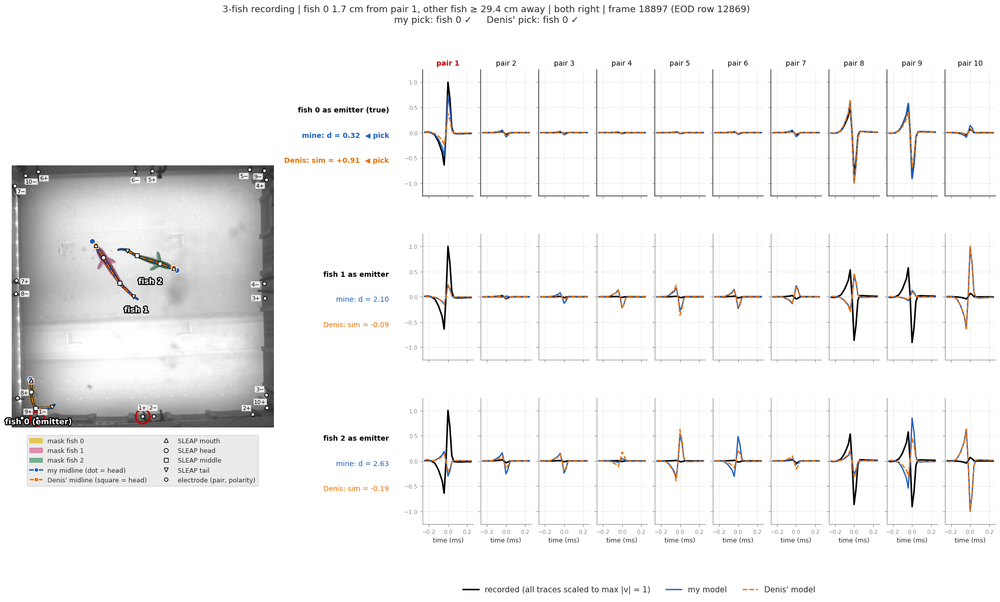

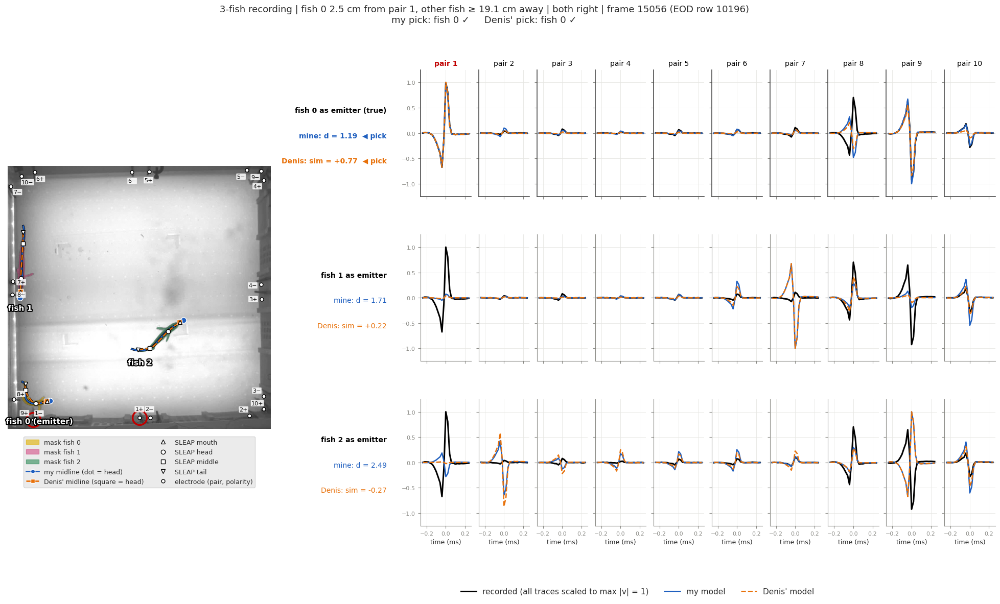

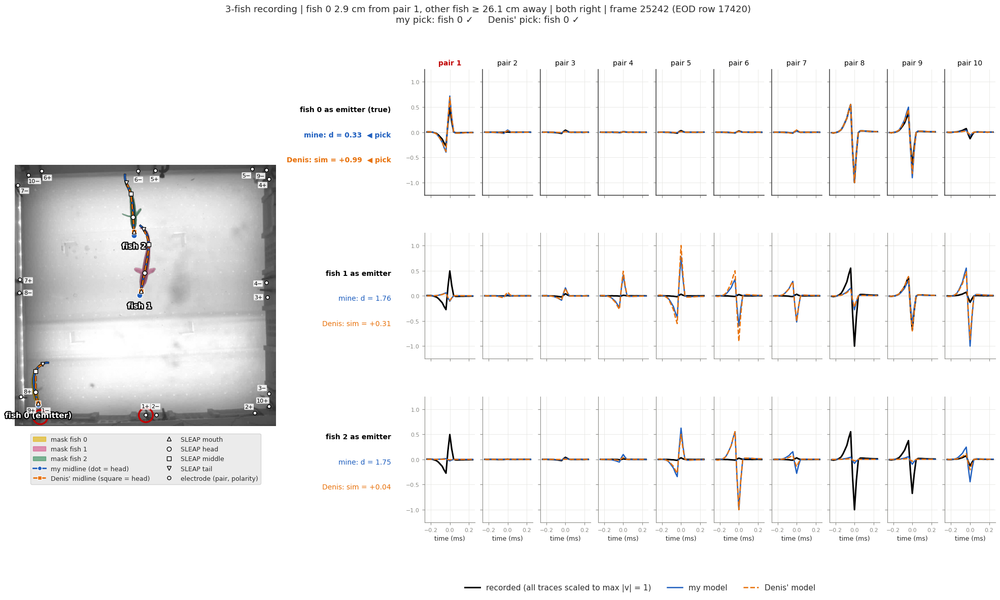

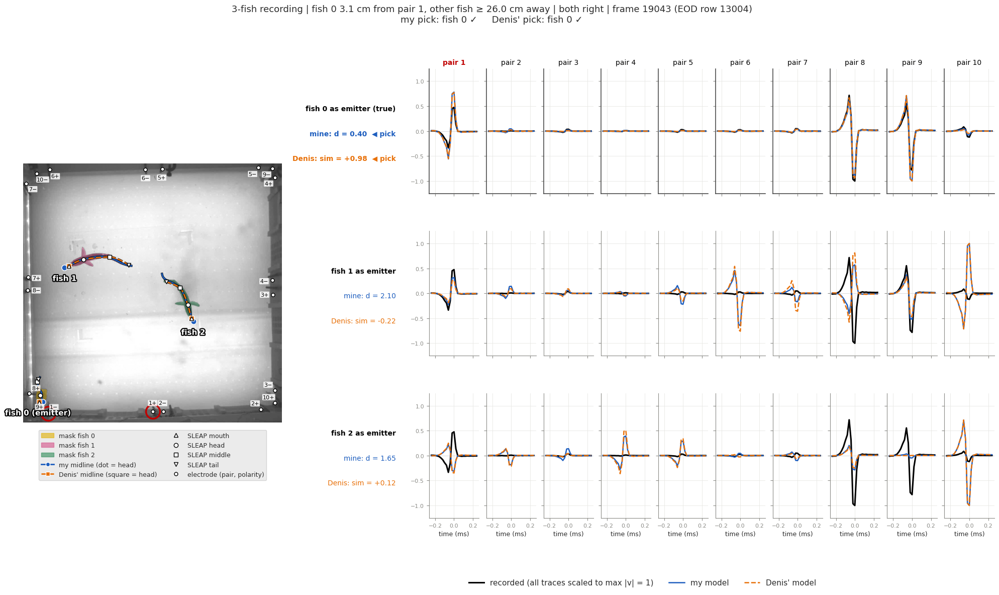

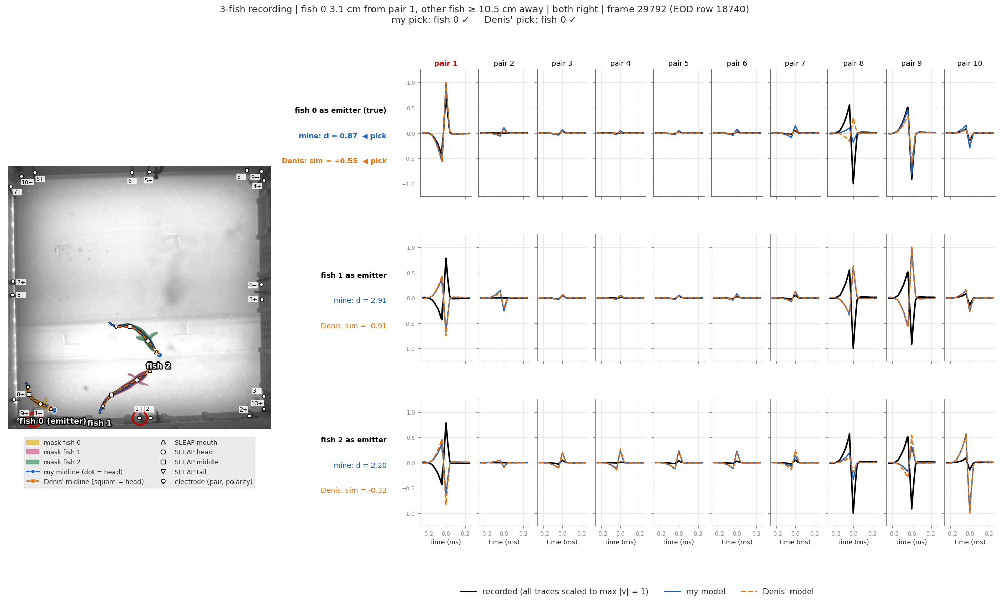

...

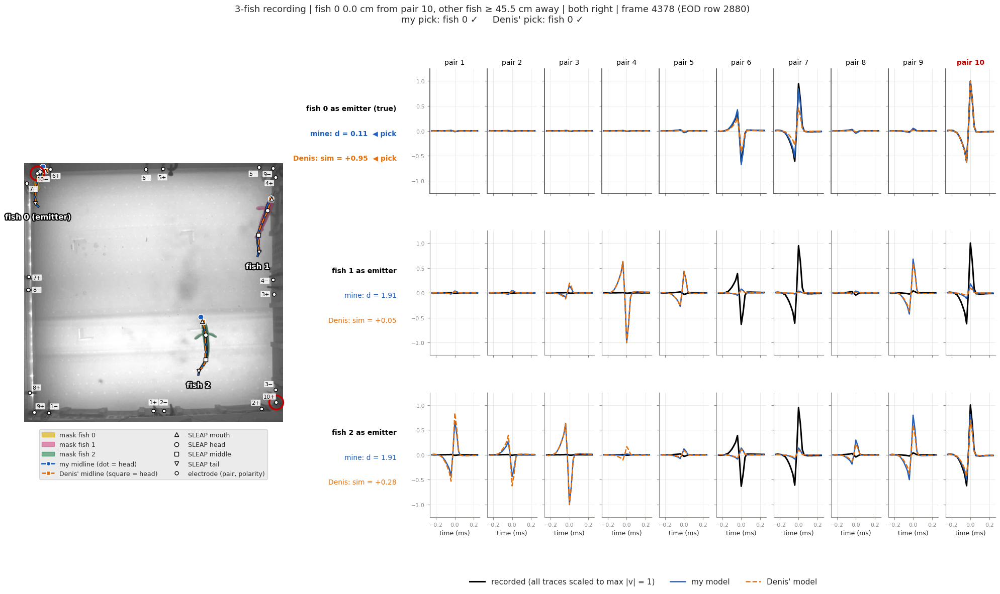

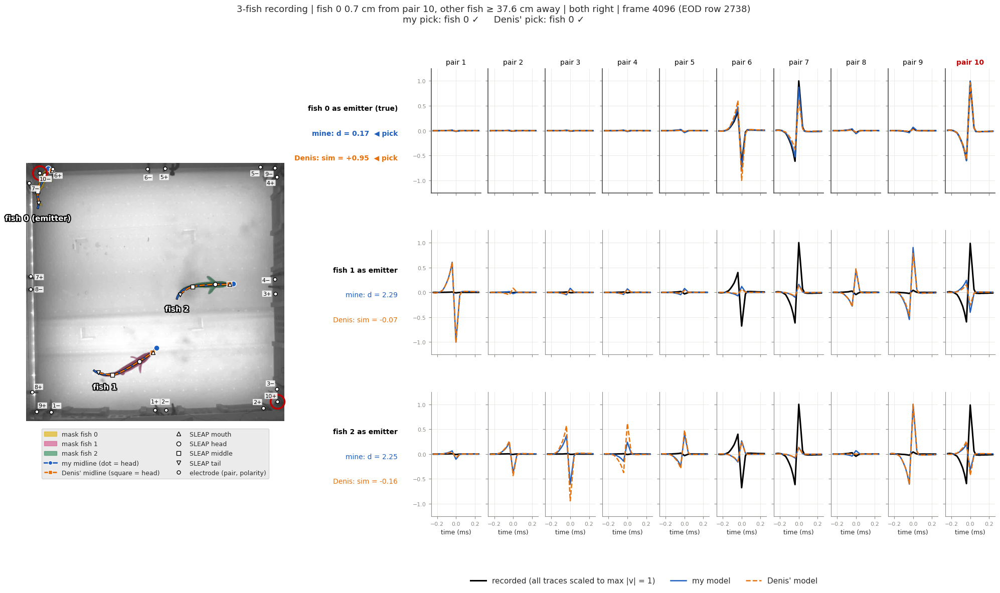

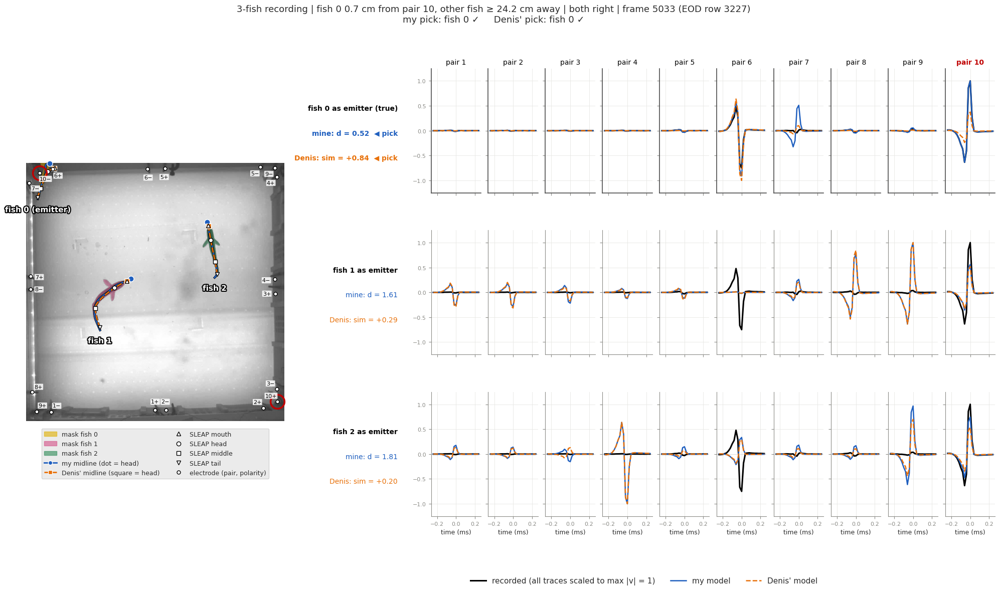

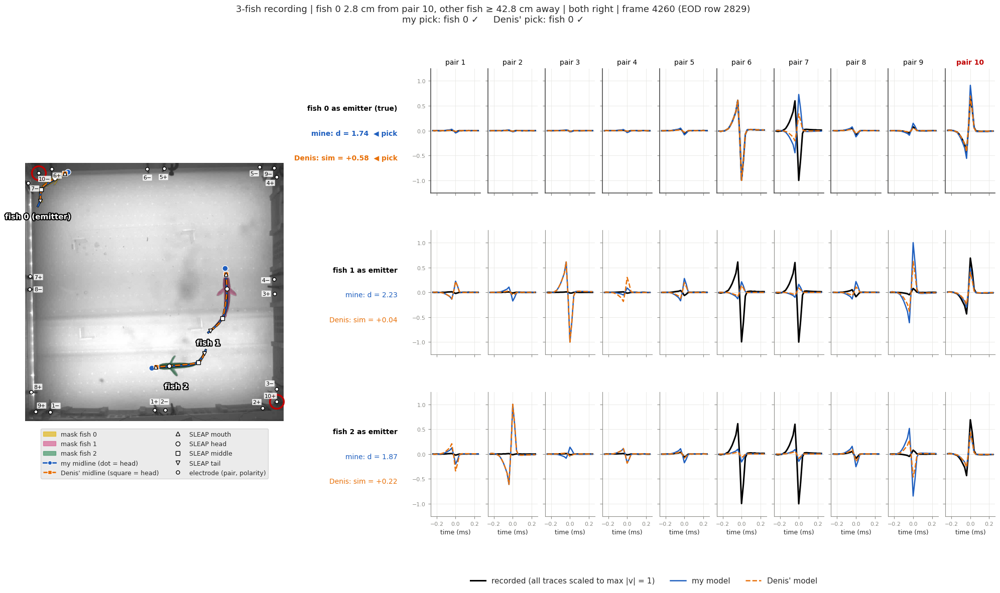

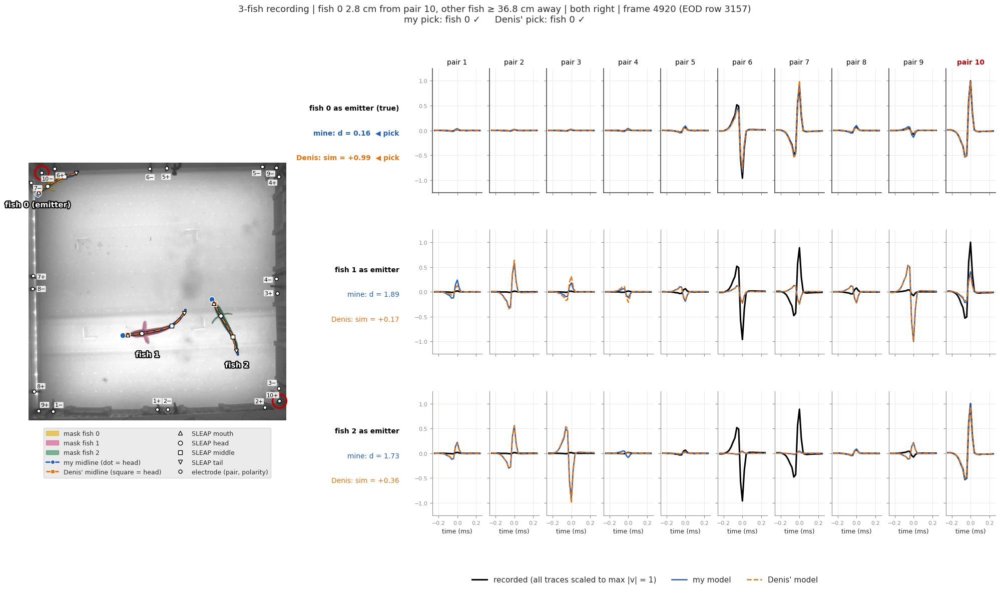

In [6]:
OUTCOME = {(True, True): 'both right', (True, False): 'only mine right', (False, True): 'only Denis right', (False, False): 'both wrong'}
for j, e in ex.iterrows():
    i, p = int(e.row), int(e.pair); n = int((ex.pair.loc[:j] == p).sum())
    o = OUTCOME[(A.loc[i, f'fish | {MINE}'] == em, A.loc[i, f'fish | {DENIS}'] == em)]
    near = '' if e['within 5 cm'] else ' (beyond 5 cm: none closer)'
    head = (f"3-fish recording | fish 0 {e['fish 0 to pair (cm)']:.1f} cm from pair {p}{near}, "
            f"other fish ≥ {e['fish 0 to nearest other fish (cm)']:.1f} cm away | {o}")
    tag = '' if e['within 5 cm'] else '_beyond5cm'
    plot_example(c, i, head, f"{OUT}/pair{p:02d}_{n}_{e['fish 0 to pair (cm)']:.1f}cm{tag}_{o.replace(' ', '_')}_frame{e.frame}.png",
                 pair=p)